Imports:

In [1]:
# %%
# ---------------------------
# System & Utilities
# ---------------------------
import os
import sys
import json
import importlib
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

sys.path.append("../src")

# ---------------------------
# Data & File Handling
# ---------------------------
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

# ---------------------------
# Visualization
# ---------------------------
import matplotlib.pyplot as plt
from matplotlib import gridspec
import seaborn as sns
import plotly.express as px

# ---------------------------
# Machine Learning
# ---------------------------
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import (
    Dataset,
    DataLoader,
    random_split,
)
from sklearn.model_selection import train_test_split

# ---------------------------
# Project Modules
# ---------------------------
from ais_to_parquet_group_by_type import fn
from download_data import (
    download_and_extract_ais_data,
    convert_ais_to_parquet_by_type,
)

import create_datasets
importlib.reload(create_datasets)

from create_datasets import (
    create_datasets,
    denormalize_xy,
    to_latlon,
    _discover_parquet_files,
    _resample_trajectory,
    _convert_latlon_to_xy,
    _apply_normalization,
)

print("All imports completed successfully!")


All imports completed successfully!


In [2]:
SHIP_TYPES = ['Cargo', 'Fishing']
SEASONS = ['Winter', 'Summer']
winter_dates = pd.date_range(start='2025-02-27', end='2025-03-01')
summer_dates = pd.date_range(start='2025-07-10', end='2025-07-12')
FILE_LIST = {}

# test with single file per season
# FILE_LIST['Winter'] = [f'aisdk-{winter_dates[0].strftime("%Y-%m-%d")}.zip']
# FILE_LIST['Summer'] = [f'aisdk-{summer_dates[0].strftime("%Y-%m-%d")}.zip']

# full file list per season
FILE_LIST['Winter'] = [f'aisdk-{date.strftime("%Y-%m-%d")}.zip' for date in winter_dates]
FILE_LIST['Summer'] = [f'aisdk-{date.strftime("%Y-%m-%d")}.zip' for date in summer_dates]

print(FILE_LIST)
BASE_URL = 'http://aisdata.ais.dk/'
PROCESSED_DIR = "../data/processed"
RAW_DATA_DIR = "../data/raw"

{'Winter': ['aisdk-2025-02-27.zip', 'aisdk-2025-02-28.zip', 'aisdk-2025-03-01.zip'], 'Summer': ['aisdk-2025-07-10.zip', 'aisdk-2025-07-11.zip', 'aisdk-2025-07-12.zip']}


This cell fetches data (only run if the data hasn't been loaded yet).

next objective: apply the preprocessing script & delete unused columns

In [3]:
# make sure directories exist
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(RAW_DATA_DIR, exist_ok=True)

for season in SEASONS:
    download_and_extract_ais_data(BASE_URL, season, FILE_LIST[season])
    convert_ais_to_parquet_by_type(season)
    

⬇️ Downloading http://aisdata.ais.dk/aisdk-2025-02-27.zip ...


  0%|                                                                                                                                   | 0.00/579M [00:00<?, ?iB/s]

  0%|▏                                                                                                                          | 923k/579M [00:00<01:02, 9.23MiB/s]

  1%|▋                                                                                                                         | 3.06M/579M [00:00<00:35, 16.4MiB/s]

  1%|█▏                                                                                                                        | 5.53M/579M [00:00<00:28, 20.2MiB/s]

  1%|█▋                                                                                                                        | 7.98M/579M [00:00<00:26, 21.9MiB/s]

... (1,267 outputs left out)

Writing data for ship type 'Towing' to ../data/processed/Summer/aisdk-2025-07-12/Towing ...
Writing data for ship type 'Not party to conflict' to ../data/processed/Summer/aisdk-2025-07-12/Not party to conflict ...


Writing data for ship type 'HSC' to ../data/processed/Summer/aisdk-2025-07-12/HSC ...
Writing data for ship type 'Spare 2' to ../data/processed/Summer/aisdk-2025-07-12/Spare 2 ...
Writing data for ship type 'Reserved' to ../data/processed/Summer/aisdk-2025-07-12/Reserved ...


Writing data for ship type 'Diving' to ../data/processed/Summer/aisdk-2025-07-12/Diving ...
Writing data for ship type 'Spare 1' to ../data/processed/Summer/aisdk-2025-07-12/Spare 1 ...
Writing data for ship type 'Anti-pollution' to ../data/processed/Summer/aisdk-2025-07-12/Anti-pollution ...
Writing data for ship type 'Towing long/wide' to ../data/processed/Summer/aisdk-2025-07-12/Towing long_wide ...


✅ Conversion complete. Parquet data stored in ../data/processed/Summer/aisdk-2025-07-12


In [4]:
# training parameters
BATCH_SIZE = 32
NUMBER_OF_EPOCHS = 40

# Some model hyperparameters
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.1

In [5]:
# LSTM model
class LSTMPredictor(nn.Module):
    def __init__(self, input_size=7, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, output_size=2, dropout=DROPOUT):
        """
        Simplified LSTM model to reduce overfitting
        """
        super(LSTMPredictor, self).__init__()
        
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # Smaller LSTM layer
        self.lstm = nn.LSTM(input_size, 
                            hidden_size, 
                            num_layers, 
                            batch_first=True, 
                            dropout=dropout if num_layers > 1 else 0.0,)
        
        # Single output layer
        self.fc = nn.Linear(hidden_size, output_size)
        
        # Add dropout for regularization
        self.dropout = nn.Dropout(dropout)
            
    def forward(self, x, hidden=None):
        # LSTM forward pass
        lstm_out, hidden = self.lstm(x, hidden)
        
        # Apply dropout
        lstm_out = self.dropout(lstm_out)

        # Use only the last output for prediction
        last_hidden = lstm_out[:, -1, :]  #(batch, hidden_size)
        
        # Output layer
        output = self.fc(last_hidden)
        
        return output

In [6]:
# GRU model
HIDDEN_SIZE = 128
NUM_LAYERS = 2
DROPOUT = 0.1

class GRUNet(nn.Module):
    def __init__(self, input_dim=7, hidden_dim=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.fc = nn.Linear(hidden_dim, 2)  # output: X, Y

    def forward(self, x):
        # x: (B, 29, 7)
        out, _ = self.gru(x)        # (B, 29, H)
        last = out[:, -1, :]        # (B, H)
        pred_xy = self.fc(last)     # (B, 2)
        return pred_xy


In [7]:
# Save the trained model
def save_model_and_training_state(model, optimizer, train_losses, val_losses, filepath):
    """
    Save model weights, optimizer state, and training history
    """
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'val_losses': val_losses,
        'epoch': len(train_losses)
    }, filepath)
    print(f"Model saved to {filepath}")

# Load the saved model
def load_model_and_training_state(filepath, is_GRU, input_size):
    """
    Load model weights, optimizer state, and training history
    """
    checkpoint = torch.load(filepath)

    if is_GRU:
        # recreate GRU model exactly like training
        model = GRUNet(
            input_dim=input_size,
            hidden_dim=HIDDEN_SIZE,
            num_layers=NUM_LAYERS,
            dropout=DROPOUT
        )
    else:
        # recreate LSTM model exactly like training
        model = LSTMPredictor(
            input_size=input_size,
            hidden_size=HIDDEN_SIZE,
            num_layers=NUM_LAYERS,
            dropout=DROPOUT
        )

    model.load_state_dict(checkpoint['model_state_dict'])

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    return model, optimizer, checkpoint['train_losses'], checkpoint['val_losses'], checkpoint['epoch']


In [8]:
# used to train both lstm and gru models
def train_setup(model):
    # Setup loss function and optimizer
    print("=== TRAINING SETUP ===")

    # Mean Squared Error loss for regression
    criterion = nn.MSELoss()

    # Adam optimizer with learning rate
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Learning rate scheduler
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

    # Training parameters
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Move model to device
    model = model.to(device)
    print(f"Model moved to: {device}")
    return criterion, optimizer, scheduler, device, model

In [9]:
def train_model(model, train_loader, val_loader, save_path):
    """
    Training loop with validation
    """


    # setup training
    criterion, optimizer, scheduler, device, model = train_setup(model)
    
    train_losses = []
    val_losses = []

    print("=== STARTING TRAINING ===")
    
    for epoch in range(NUMBER_OF_EPOCHS):
        # Training phase
        model.train()
        train_loss = 0.0
        
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            inputs, targets = inputs.to(device), targets.to(device)
            
            # Zero gradients
            optimizer.zero_grad()
            
            # Forward pass  (GRU returns ONLY outputs)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        # Validation phase
        model.eval()
        val_loss = 0.0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)  # no "_"
                loss = criterion(outputs, targets)
                val_loss += loss.item()
        
        # Average losses
        train_loss /= len(train_loader)
        val_loss /= len(val_loader)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        # Update learning rate
        scheduler.step(val_loss)
        
        # Print progress
        current_lr = optimizer.param_groups[0]['lr']
        print(f'Epoch [{epoch+1:02d}/{NUMBER_OF_EPOCHS}] | '
                f'Train Loss: {train_loss:.6f} | '
                f'Val Loss: {val_loss:.6f} | '
                f'LR: {current_lr:.6f}')
    
    print("Training completed!")

    # Save after training  (CHANGE FILE NAME !!)
    save_model_and_training_state(model, optimizer, train_losses, val_losses, filepath=save_path)

    print("Parameters saved after training.\n")

    return train_losses, val_losses

In [10]:
def lstm(device, train, val, test, save_path):
    train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False)

    input_size = train[0][0].shape[1]  # number of features

    model = LSTMPredictor(
    input_size=input_size
    ).to(device)

    # training
    train_losses, val_losses = train_model(model, train_loader, val_loader, save_path)    
    return model, test_loader, train_losses, val_losses

In [11]:
def gru(device, train, val, test, save_path):
    train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False)

    input_size = train[0][0].shape[1]  # number of features

    model = GRUNet(
            input_dim=input_size,
            hidden_dim=HIDDEN_SIZE,
            num_layers=NUM_LAYERS,
            dropout=DROPOUT
        ).to(device)

    # training
    train_losses, val_losses = train_model(model, train_loader, val_loader, save_path)    

    return model, test_loader, train_losses, val_losses

In [12]:
# function plotting training and validation error
def plot_training_validation_error(train_losses, val_losses, title):
    plt.figure(figsize=(10, 6))
    plt.plot(train_losses, label='Training Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

In [13]:
def speed_analysis(model, test_loader, device, json_dir, title):
    """
    Analyze speed prediction performance
    """

    all_errors = []
    all_speeds_knots = []
    all_lon = []
    all_lat = []

    model.eval()
    TIME_STEP = 60.0              # seconds between samples in your sequences
    KNOTS_PER_MPS = 1.0 / 0.514444  # m/s -> knots

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            # shapes: inputs (B, 29, 7), targets (B, 2)
            batch_inputs  = batch_inputs.to(device)
            batch_targets = batch_targets.to(device)

            # predict normalized X,Y
            batch_outputs = model(batch_inputs)

            # move to numpy
            inputs_np  = batch_inputs.cpu().numpy()
            targets_np = batch_targets.cpu().numpy()
            outputs_np = batch_outputs.cpu().numpy()

            B = inputs_np.shape[0]

            # ---- denormalize true & predicted XY ----
            true_xy_den = denormalize_xy(targets_np, json_dir)   # (B,2)
            pred_xy_den = denormalize_xy(outputs_np, json_dir)   # (B,2)

            # ---- error in meters ----
            err = np.linalg.norm(true_xy_den - pred_xy_den, axis=1)  # (B,)
            all_errors.extend(err.tolist())

            # ---- speed estimate from last two points of input ----
            last2_xy_norm = inputs_np[:, -2:, :2].reshape(-1, 2)    # (2B,2)
            last2_xy_den  = denormalize_xy(last2_xy_norm, json_dir)           # (2B,2)
            last2_xy_den  = last2_xy_den.reshape(B, 2, 2)           # (B,2,2)

            dxdy = last2_xy_den[:, 1, :] - last2_xy_den[:, 0, :]
            dist = np.linalg.norm(dxdy, axis=1)      # meters in 60 seconds
            speed_mps = dist / TIME_STEP
            speed_knots = speed_mps * KNOTS_PER_MPS
            all_speeds_knots.extend(speed_knots.tolist())

            # ---- true target position in lat/lon for maps ----
            ll = to_latlon(true_xy_den, json_dir)  # (B,2): lon, lat
            all_lon.extend(ll[:, 0].tolist())
            all_lat.extend(ll[:, 1].tolist())

    print(len(all_errors), len(all_speeds_knots), len(all_lon))

    
    df_err = pd.DataFrame({
        "error":       all_errors,        # prediction error in meters
        "speed_knots": all_speeds_knots,  # estimated speed in knots
        "lon":         all_lon,           # longitude of target point
        "lat":         all_lat            # latitude of target point
    })

    # Clean up crazy outliers / NaNs if any
    df_err = df_err.replace([np.inf, -np.inf], np.nan).dropna()
    df_err = df_err[df_err["error"] < 1e6]   # this is OK only for visualization but it removes the point where we there might be anomalies

    print(df_err.head())
    print("Number of points in df_err:", len(df_err))

    errors = np.array(all_errors)
    speeds = np.array(all_speeds_knots)

    bins = [0, 2, 5, 10, 15, 20, 100]  # knots
    labels = ["0-2", "2-5", "5-10", "10-15", "15-20", "20+"]

    speed_bin = pd.cut(speeds, bins=bins, labels=labels, include_lowest=True)

    df_speed_err = pd.DataFrame({
        "speed_bin": speed_bin,
        "error": errors
    }).dropna()

    mean_err_by_bin = df_speed_err.groupby("speed_bin")["error"].mean()
    count_by_bin    = df_speed_err["speed_bin"].value_counts().sort_index()

    plt.figure(figsize=(7,4))
    mean_err_by_bin.plot(kind="bar", edgecolor="k")
    plt.ylabel("Mean error (m)")
    plt.xlabel("Speed bin (knots)")
    plt.title(title)
    plt.grid(axis="y", alpha=0.3)
    plt.show()

    print("Counts per speed bin:")
    print(count_by_bin)

    return df_err



In [14]:
def in_box(df, north, west, south, east):
    """Return boolean mask for points inside a lon/lat rectangle."""
    return (
        (df["lat"] <= north) &
        (df["lat"] >= south) &
        (df["lon"] >= west) &
        (df["lon"] <= east)
    )

def in_open_sea(df):
    """
    Rough 'open sea' west of Denmark (North Sea / Skagerrak).
    Tweak numbers if you want to move the cyan box.
    """
    return in_box(
        df,
        north=59.5,   # top
        south=54.5,   # bottom
        west=3.5,     # left (more towards open ocean)
        east=8.5      # right (before Jutland coast)
    )

def in_strait(df):
    """
    Narrow strait around Storebælt / Øresund.
    These bounds correspond roughly to your magenta box.
    """
    return in_box(
        df,
        north=56.9,   # top
        south=54.8,   # bottom
        west=9.5,     # left
        east=12.5     # right
    )

def heatmap_analysis(df_err):
    """
    Analyze spatial prediction performance
    """

    # To avoid lag, randomly sample up to 50k points
    if len(df_err) > 50000:
        df_plot = df_err.sample(n=50000, random_state=0)
    else:
        df_plot = df_err.copy()

    df_plot["error_vis"] = df_plot["error"].clip(upper=np.percentile(df_plot["error"], 95))
    # Base scatter on map: points colored by error
    fig = px.scatter_mapbox(
        df_plot,
        lat="lat",
        lon="lon",
        color="error_vis",
        color_continuous_scale="Inferno",
        zoom=5.5,                          
        height=750,
        opacity=0.5,
        mapbox_style="open-street-map",
        center=dict(lat=56.0, lon=11.0)    # center on Denmark
    )
    # Function to draw a rectangular region as a polygon
    # def add_region_box(fig, box, name, color):
    #     lats_box = [
    #         box["lat_min"],
    #         box["lat_min"],
    #         box["lat_max"],
    #         box["lat_max"],
    #         box["lat_min"],
    #     ]
    #     lons_box = [
    #         box["lon_min"],
    #         box["lon_max"],
    #         box["lon_max"],
    #         box["lon_min"],
    #         box["lon_min"],
    #     ]

    #     # outline
    #     fig.add_trace(go.Scattermapbox(
    #         lat=lats_box,
    #         lon=lons_box,
    #         mode="lines",
    #         line=dict(width=3, color=color),
    #         name=name.replace("_", " ").title(),
    #     ))

    #     # label in the middle
    #     center_lat = 0.5 * (box["lat_min"] + box["lat_max"])
    #     center_lon = 0.5 * (box["lon_min"] + box["lon_max"])

    #     fig.add_trace(go.Scattermapbox(
    #         lat=[center_lat],
    #         lon=[center_lon],
    #         mode="markers+text",
    #         text=[name.replace("_", " ").title()],
    #         textposition="top center",
    #         marker=dict(size=8, color=color),
    #         showlegend=False,
    #     ))

    # Add the two boxes
    # add_region_box(fig, REGIONS["open_sea"], "open_sea", "cyan")
    # add_region_box(fig, REGIONS["narrow_strait"], "narrow_strait", "magenta")

    fig.update_layout(
        title=(
            "LSTM prediction error around Denmark<br>"
            "<sub>Colored points = error (m). Cyan box = 'open sea', "
            "Magenta box = 'narrow strait'.</sub>"
        ),
    )

    fig.show()


In [15]:
def full_workflow(season, ship_type):
    # folder for normalization parameters
    json_dir = f'../data/normalization/{season.lower()}_{ship_type.lower()}'
    os.makedirs(json_dir, exist_ok=True)
    # create datasets
    train_dataset, val_dataset, test_dataset = create_datasets(input_files='../data/processed/'+season , ship_type=ship_type, with_full_data=True, json_dir=json_dir)

    # find device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # train lstm model
    model_dir = '../models'
    os.makedirs(model_dir, exist_ok=True)
    save_path = f'{model_dir}/lstm_model_{season.lower()}_{ship_type.lower()}.pth'
    model, test_loader, train_losses, val_losses = lstm(device, train_dataset, val_dataset, test_dataset, save_path)

    # analaysis
    title = f'LSTM Training and Validation Loss ({season} - {ship_type})'
    plot_training_validation_error(train_losses, val_losses, title)
    df_err = speed_analysis(model, test_loader, device, json_dir, title)
    heatmap_analysis(df_err)

    # # train gru model
    # save_path = f'{model_dir}/gru_model_{season.lower()}_{ship_type.lower()}.pth'
    # model, test_loader, train_losses, val_losses = gru(device, train_dataset, val_dataset, test_dataset, save_path)

    # # analaysis
    # title = f'GRU Training and Validation Loss ({season} - {ship_type})'
    # plot_training_validation_error(train_losses, val_losses, title)
    # title = f'GRU Speed Analysis ({season} - {ship_type})'
    # df_err = speed_analysis(model, test_loader, device, json_dir, title)
    # heatmap_analysis(df_err)

Discovered 1446 parquet files from 741 vessels.


Total loaded trajectories: 1446


  Split into 1 segments due to large gaps


  Split into 1 segments due to large gaps


  Split into 1 segments due to large gaps


Total resampled trajectories: 1444


... (38 outputs left out)

Epoch [37/40] | Train Loss: 0.003521 | Val Loss: 0.000068 | LR: 0.000500


Epoch [38/40] | Train Loss: 0.003532 | Val Loss: 0.000051 | LR: 0.000500


Epoch [39/40] | Train Loss: 0.003526 | Val Loss: 0.000083 | LR: 0.000500


Epoch [40/40] | Train Loss: 0.003526 | Val Loss: 0.000061 | LR: 0.000500
Training completed!
Model saved to ../models/lstm_model_winter_cargo.pth
Parameters saved after training.



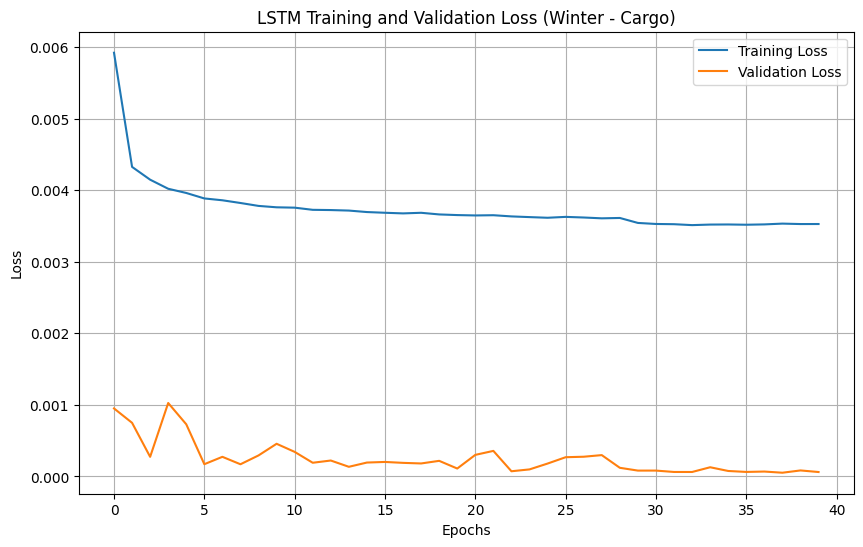

143822 143822 143822
         error  speed_knots        lon        lat
0  1413.977289     8.830092  10.712776  57.299433
1  1413.624619     8.938404  10.712439  57.296987
2  1409.826228     8.837640  10.712081  57.294564
3  1405.427251     8.757723  10.711699  57.292081
4  1404.050103     8.978353  10.711318  57.289585
Number of points in df_err: 143822


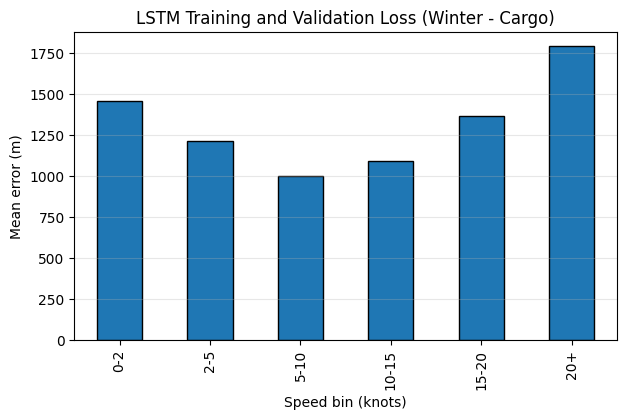

Counts per speed bin:
speed_bin
0-2      18759
2-5       1699
5-10     36734
10-15    71507
15-20    13536
20+       1490
Name: count, dtype: int64


Discovered 723 parquet files from 334 vessels.


Total loaded trajectories: 723
  Split into 2 segments due to large gaps


  Split into 1 segments due to large gaps
  Split into 2 segments due to large gaps


  Split into 0 segments due to large gaps


  Split into 1 segments due to large gaps
  Split into 0 segments due to large gaps


... (44 outputs left out)

Epoch [37/40] | Train Loss: 0.003479 | Val Loss: 0.000057 | LR: 0.000125


Epoch [38/40] | Train Loss: 0.003498 | Val Loss: 0.000018 | LR: 0.000125


Epoch [39/40] | Train Loss: 0.003501 | Val Loss: 0.000033 | LR: 0.000125


Epoch [40/40] | Train Loss: 0.003471 | Val Loss: 0.000049 | LR: 0.000125
Training completed!
Model saved to ../models/lstm_model_winter_fishing.pth
Parameters saved after training.



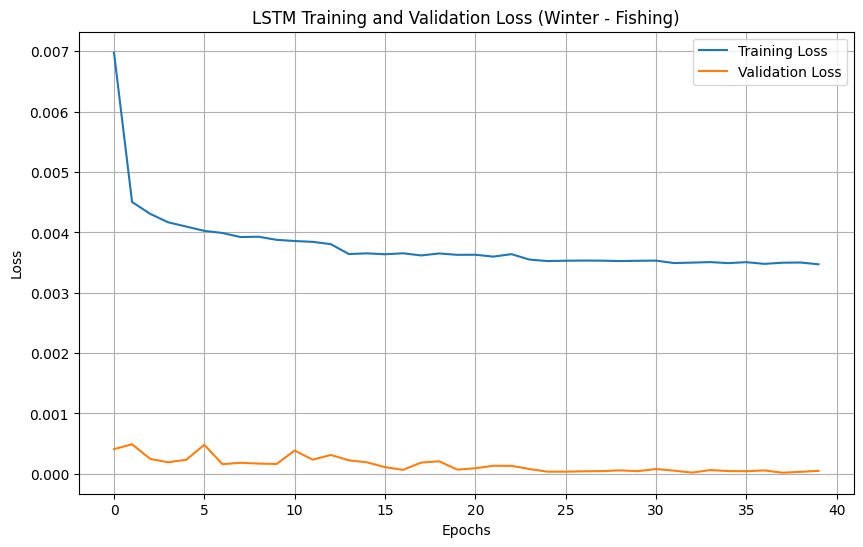

74580 74580 74580
        error  speed_knots       lon        lat
0  466.788858     0.002851  9.962765  57.593889
1  466.570481     0.007299  9.962773  57.593889
2  466.752137     0.015056  9.962772  57.593887
3  466.984435     0.008083  9.962769  57.593888
4  466.509028     0.008186  9.962772  57.593888
Number of points in df_err: 74580


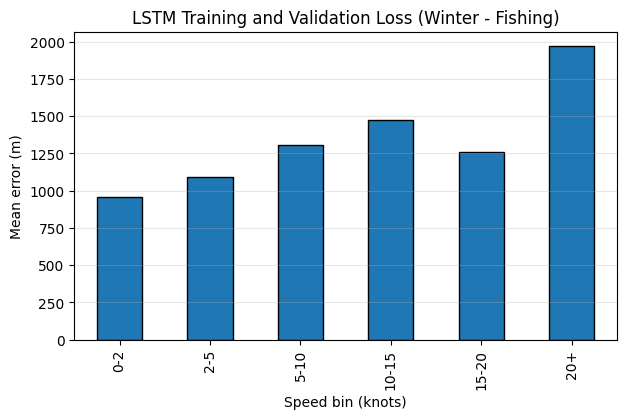

Counts per speed bin:
speed_bin
0-2      26499
2-5      30025
5-10     14882
10-15     2992
15-20       76
20+        101
Name: count, dtype: int64


Discovered 1640 parquet files from 798 vessels.


Total loaded trajectories: 1640


  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps


  Split into 1 segments due to large gaps


  Split into 2 segments due to large gaps


... (42 outputs left out)

Epoch [37/40] | Train Loss: 0.003571 | Val Loss: 0.000036 | LR: 0.000250


Epoch [38/40] | Train Loss: 0.003572 | Val Loss: 0.000059 | LR: 0.000125


Epoch [39/40] | Train Loss: 0.003554 | Val Loss: 0.000048 | LR: 0.000125


Epoch [40/40] | Train Loss: 0.003533 | Val Loss: 0.000040 | LR: 0.000125
Training completed!
Model saved to ../models/lstm_model_summer_cargo.pth
Parameters saved after training.



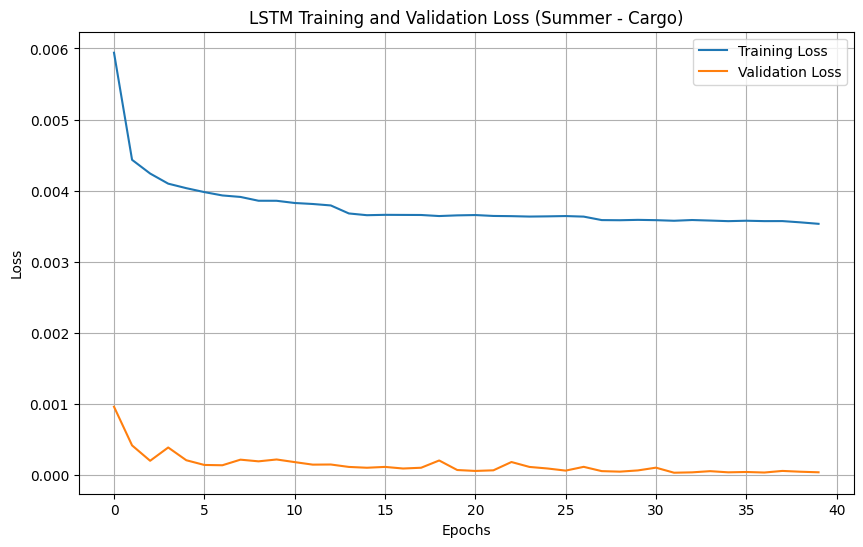

147964 147964 147964
         error  speed_knots       lon        lat
0   963.116119    12.411424  4.466148  55.491960
1  1023.396655    11.179119  4.465542  55.495705
2   982.105781    13.543788  4.464895  55.499274
3   960.181312    12.923563  4.464353  55.502604
4   940.960917    12.046139  4.463942  55.505557
Number of points in df_err: 147964


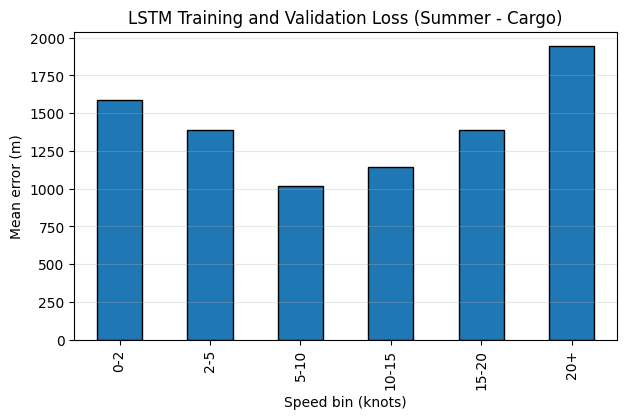

Counts per speed bin:
speed_bin
0-2      21287
2-5       3523
5-10     52311
10-15    57691
15-20    10453
20+       2586
Name: count, dtype: int64


Discovered 817 parquet files from 376 vessels.


Total loaded trajectories: 817
  Split into 5 segments due to large gaps


  Split into 1 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps


  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps


  Split into 0 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps


... (46 outputs left out)

Epoch [37/40] | Train Loss: 0.003445 | Val Loss: 0.000165 | LR: 0.000250


Epoch [38/40] | Train Loss: 0.003464 | Val Loss: 0.000051 | LR: 0.000250


Epoch [39/40] | Train Loss: 0.003457 | Val Loss: 0.000066 | LR: 0.000125


Epoch [40/40] | Train Loss: 0.003429 | Val Loss: 0.000071 | LR: 0.000125
Training completed!
Model saved to ../models/lstm_model_summer_fishing.pth
Parameters saved after training.



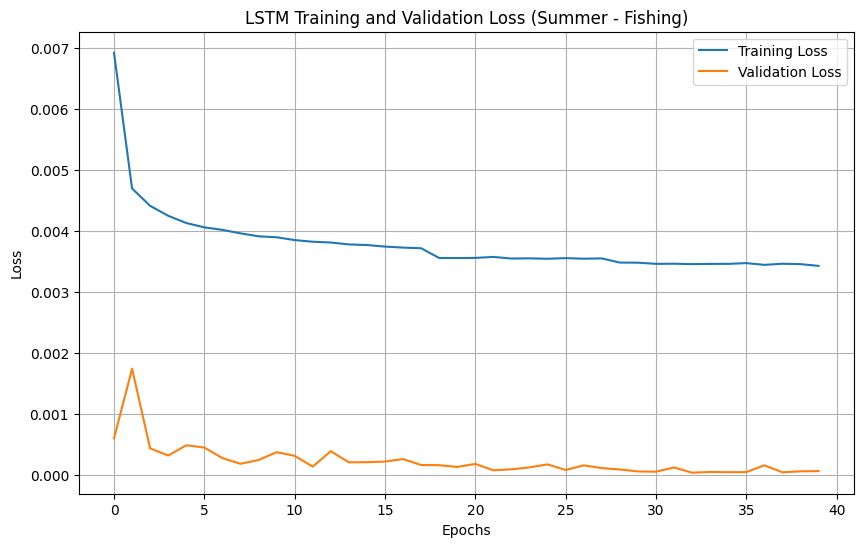

102320 102320 102320
        error  speed_knots       lon        lat
0  282.218585     0.022784  9.956078  57.593144
1  275.123689     0.020458  9.956073  57.593148
2  271.458818     0.018451  9.956074  57.593145
3  273.357953     0.009904  9.956082  57.593122
4  270.823463     0.085368  9.956079  57.593126
Number of points in df_err: 102320


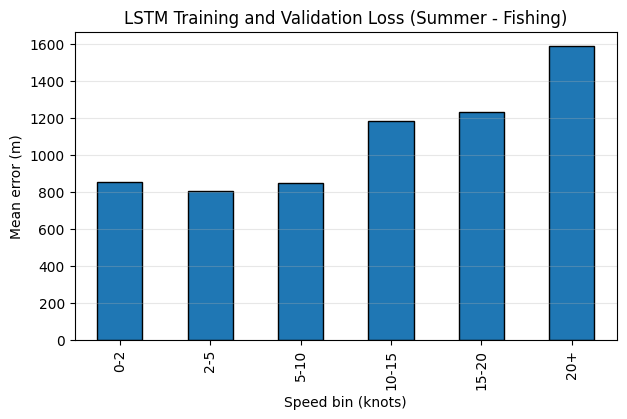

Counts per speed bin:
speed_bin
0-2      54182
2-5      29327
5-10     16937
10-15     1448
15-20      214
20+        209
Name: count, dtype: int64


In [16]:
for season in SEASONS:
    for ship_type in SHIP_TYPES:
        full_workflow(season, ship_type)